In [2]:
22+22

44

In [3]:
#导入 Numpy 并重名为 np
import numpy as np
#生成元素为 0 到 5 的整数（不包括 5）的数组
x = np.arange(5)
#生成元素为 3 到 9的整数（不包括 9）、步长为2的数组
x1 = np.arange(3,9,2)
print("x:",x,"x1:",x1)

x: [0 1 2 3 4] x1: [3 5 7]


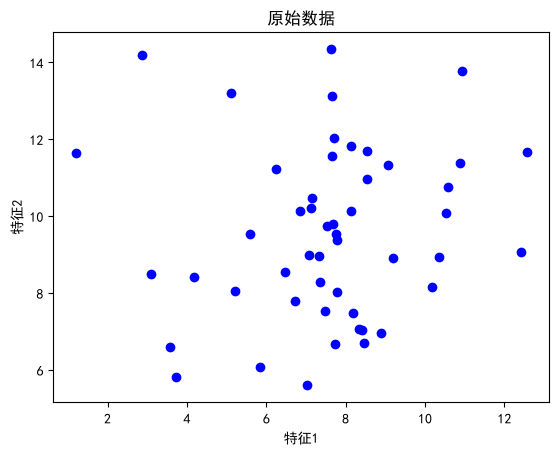

In [4]:
%matplotlib inline
#导入绘图工具
import matplotlib.pyplot as plt
# 导入数据集生成工具
from sklearn.datasets import make_blobs
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
# 生成一个样本数为1、标准差为1的数据集
X, y = make_blobs(n_samples=50, centers=1, cluster_std=2, random_state=8)
# 用散点图绘制数据点
plt.scatter(X[:, 0], X[:, 1], c='blue')
plt.xlabel('特征1')
plt.ylabel('特征2')
plt.title('原始数据')
plt.show()

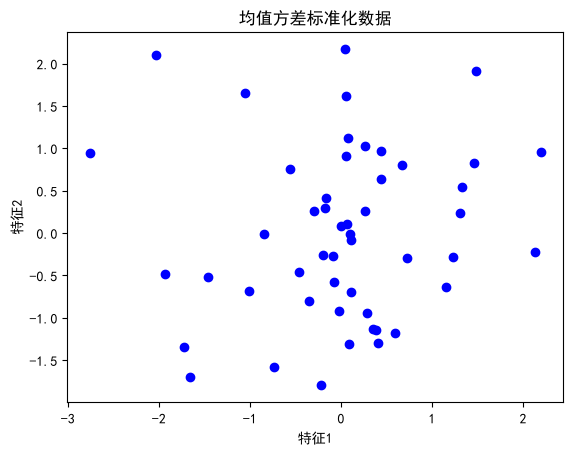

In [5]:
# 导入StandardScaler
from sklearn.preprocessing import StandardScaler
# 使用StandardScaler进行数据处理
scaler = StandardScaler().fit(X)
X_1 = scaler.transform(X)
# 也可以用fit_transform()实现
# X_1 = StandardScaler().fit_transform(X)
# 用散点图绘制经过预处理的数据点
plt.scatter(X_1[:, 0], X_1[:, 1], c='blue')
plt.xlabel('特征1')
plt.ylabel('特征2')
plt.title('均值方差标准化数据')
plt.show()

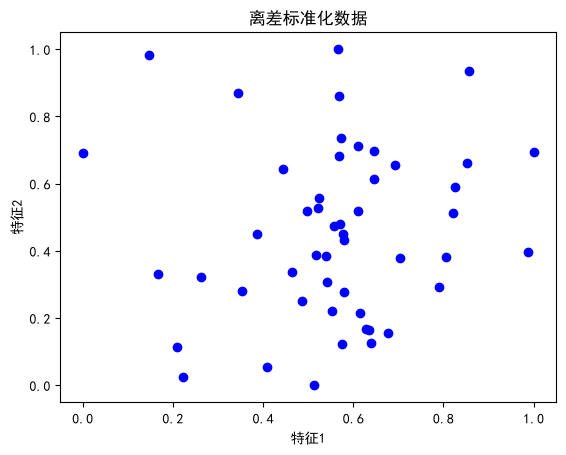

In [6]:
# 导入MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
# 使用MinMaxScaler进行数据预处理
X_2 = MinMaxScaler().fit_transform(X)
# 绘制散点图
plt.scatter(X_2[:, 0], X_2[:, 1], c='blue')
plt.xlabel('特征1')
plt.ylabel('特征2')
plt.title('离差标准化数据')
plt.show()

In [7]:
import numpy as np
# 导入Binarizer
from sklearn.preprocessing import Binarizer

data = np.array([[ 3, -1.5,  2, -5.4],
                 [ 0,  4,  -0.3, 2.1],
                 [ 1,  3.3, -1.9, -4.3]])
# 数据二值化
data_binarized = Binarizer(threshold=1.4).transform(data)
print("二值化处理后的数据：\n", data_binarized)

二值化处理后的数据：
 [[1. 0. 1. 0.]
 [0. 1. 0. 1.]
 [0. 1. 0. 0.]]


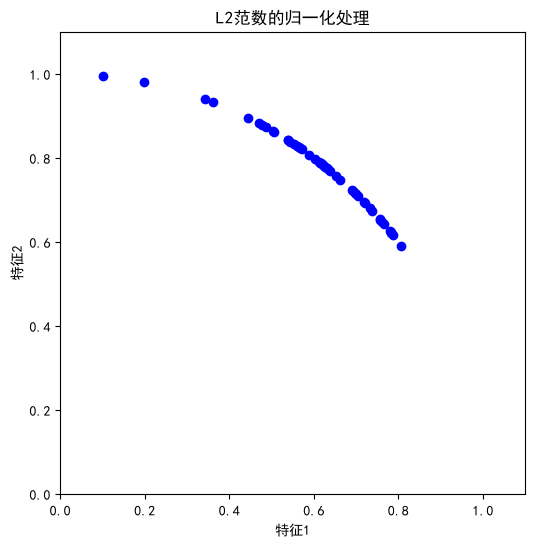

In [8]:
# 导入Normalizer
from sklearn.preprocessing import Normalizer
# 使用Normalizer进行数据预处理，默认为L2范数
# 将所有样本的特征向量转化为欧几里得距离为 1；通常在只想保留数据
# 数值的时候使用
X_3 = Normalizer().fit_transform(X)
# 绘制散点图
plt.figure(figsize=(6, 6))
plt.scatter(X_3[:, 0], X_3[:, 1], c='blue')
plt.xlim(0, 1.1)
plt.ylim(0, 1.1)
plt.xlabel('特征1')
plt.ylabel('特征2')
plt.title('L2范数的归一化处理')
plt.show()

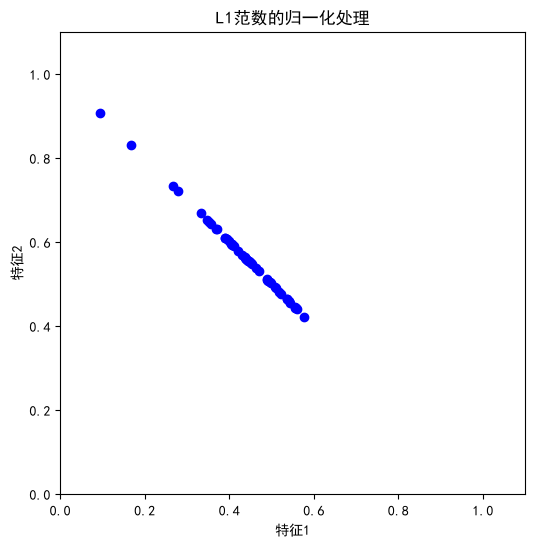

In [9]:
# 修改norm参数为 L1 范数
X_4 = Normalizer(norm='l1').fit_transform(X)
# 绘制散点图
plt.figure(figsize=(6, 6))
plt.scatter(X_4[:, 0], X_4[:, 1], c='blue')
plt.xlim(0, 1.1)
plt.ylim(0, 1.1)
plt.xlabel('特征1')
plt.ylabel('特征2')
plt.title('L1范数的归一化处理')
plt.show()

In [10]:
import numpy as np
# 导入OneHotEncoder
from sklearn.preprocessing import OneHotEncoder
# 原始数据
data_type = np.array([[0, 1],
                      [1, 3],
                      [2, 0],
                      [1, 2]])
# 进行独热编码
encoder = OneHotEncoder(categories='auto')
data_encoded = encoder.fit_transform(data_type).toarray()
print("编码后的数据：\n", data_encoded)

编码后的数据：
 [[1. 0. 0. 0. 1. 0. 0.]
 [0. 1. 0. 0. 0. 0. 1.]
 [0. 0. 1. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 1. 0.]]


In [11]:
import numpy as np
# 定义一个随机数的数组
np.random.seed(38)
arr = np.random.uniform(-5, 5, size=20)
# 设置箱体数为 5
bins = np.linspace(-5, 5, 6)
# 将数据进行装箱操作
target_bin = np.digitize(arr, bins=bins)
# 输出装箱数据范围
print('装箱数据范围：\n{}'.format(bins))
print('\n数据点的特征值：\n{}'.format(arr))
print('\n数据点所在的箱子：\n{}'.format(target_bin))

装箱数据范围：
[-5. -3. -1.  1.  3.  5.]

数据点的特征值：
[-1.1522688   3.59707847  4.44199636  2.02824894  1.33634097  1.05961282
 -2.99873157 -1.12612112 -2.41016836 -4.25392719 -2.19043025 -0.61565849
 -0.16750956  3.68489486  0.29629384  0.62263144 -0.28944656  1.88842007
  0.04828605  3.23175755]

数据点所在的箱子：
[2 5 5 4 4 4 2 2 2 1 2 3 3 5 3 3 3 4 3 5]


In [12]:
# 导入独热编码
import numpy as np
from sklearn.preprocessing import OneHotEncoder
target_bin = np.array([2,5,5,4,4,4,2,2,1,2,3,3,5,3,3,3,4,3,5])
target_bin = target_bin.reshape(-1, 1)
onehot = OneHotEncoder(sparse_output=False, categories='auto')
onehot.fit(target_bin)
# 使用独热编码转化数据
arr_in_bin = onehot.transform(target_bin)
# 输出结果
print('装箱编码后的数据维度：{}'.format(arr_in_bin.shape))
print('\n装箱编码后的数值：\n{}'.format(arr_in_bin))

装箱编码后的数据维度：(19, 5)

装箱编码后的数值：
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1.]]


In [13]:
# 导入iris数据集
from sklearn.datasets import load_iris
# 加载iris数据集
iris = load_iris()
X = iris.data
print('iris数据集的维度为：', X.shape)
print('iris数据集的前5行数据为：\n', X[:5])

iris数据集的维度为： (150, 4)
iris数据集的前5行数据为：
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


In [14]:
# 导入PCA
from sklearn.decomposition import PCA
# 指定保留的特征数为3
pca_num = PCA(n_components=3)
# 训练PCA模型
pca_num.fit(X)
# 对样本数据进行降维
X_pcal = pca_num.transform(X)
# 查看降维结果
print('对iris数据集进行指定特征数的降维后的维度为：', X_pcal.shape)

对iris数据集进行指定特征数的降维后的维度为： (150, 3)


In [15]:
print('进行指定特征数降维后，iris数据集的前5行数据为：\n', X_pcal[:5])

进行指定特征数降维后，iris数据集的前5行数据为：
 [[-2.68412563  0.31939725 -0.02791483]
 [-2.71414169 -0.17700123 -0.21046427]
 [-2.88899057 -0.14494943  0.01790026]
 [-2.74534286 -0.31829898  0.03155937]
 [-2.72871654  0.32675451  0.09007924]]


In [16]:
import numpy as np
print('进行指定特征数的降维后的最大方差的成分：')
for i in range(pca_num.components_.shape[0]):
    arr = np.around(pca_num.components_[i], 2)
    print('component{}: {}'.format((i+1), [x for x in arr]))

进行指定特征数的降维后的最大方差的成分：
component1: [np.float64(0.36), np.float64(-0.08), np.float64(0.86), np.float64(0.36)]
component2: [np.float64(0.66), np.float64(0.73), np.float64(-0.17), np.float64(-0.08)]
component3: [np.float64(-0.58), np.float64(0.6), np.float64(0.08), np.float64(0.55)]


In [17]:
var = np.around(pca_num.explained_variance_, 2)
print('进行指定特征数的降维后的各主成分的方差为：', [x for x in var])
var_ratio = np.round(pca_num.explained_variance_ratio_, 2)
print('进行指定特征数的降维后的各主成分的方差百分比为：', [x for x in var_ratio])


进行指定特征数的降维后的各主成分的方差为： [np.float64(4.23), np.float64(0.24), np.float64(0.08)]
进行指定特征数的降维后的各主成分的方差百分比为： [np.float64(0.92), np.float64(0.05), np.float64(0.02)]


In [18]:
# 指定保留的方差百分比为0.95
pca_per = PCA(n_components=0.95)
# 训练PCA模型
pca_per.fit(X)
# 对样本数据进行降维
X_pca2 = pca_per.transform(X)
# 查看降维结果
print('对iris数据集进行指定方差百分比的降维后的维度为：', X_pca2.shape)


对iris数据集进行指定方差百分比的降维后的维度为： (150, 2)


In [19]:
print('进行指定方差百分比的降维后iris数据集的前5行数据为：\n', X_pca2[:5])


进行指定方差百分比的降维后iris数据集的前5行数据为：
 [[-2.68412563  0.31939725]
 [-2.71414169 -0.17700123]
 [-2.88899057 -0.14494943]
 [-2.74534286 -0.31829898]
 [-2.72871654  0.32675451]]


In [20]:
print('进行指定方差百分比降维后的最大方差的成分：')
for i in range(pca_per.components_.shape[0]):
    arr = np.round(pca_per.components_[i], 2).tolist()
    print('component{}: {}'.format((i+1), arr))

进行指定方差百分比降维后的最大方差的成分：
component1: [0.36, -0.08, 0.86, 0.36]
component2: [0.66, 0.73, -0.17, -0.08]


In [21]:
var = np.round(pca_per.explained_variance_, 2).tolist()
print('进行指定方差百分比的降维后的各主成分的方差为：', var)
var_ratio = np.round(pca_per.explained_variance_ratio_, 2).tolist()
print('进行指定方差百分比的降维后的各主成分的方差百分比为：', var_ratio)

进行指定方差百分比的降维后的各主成分的方差为： [4.23, 0.24]
进行指定方差百分比的降维后的各主成分的方差百分比为： [0.92, 0.05]
